# Rocket Science — Takeoff and Landing

Launching a booster and landing it are control-and-estimation problems. This notebook
tracks three phases of powered flight near Earth. Each phase uses an Extended Kalman
Filter, or EKF, over a different model from `kalman.apps.astro.rocket`.

1. **Liftoff** — a 1-D vertical climb. The rocket burns propellant, so its mass
   decreases (the Tsiolkovsky rocket equation). Acceleration rises until burnout.
2. **Guided ascent** — a 2-D climb where thrust is the control input `u`.
3. **Powered descent and landing** — a 2-D rigid booster (a rectangle with
   orientation) that gimbals its engine and adjusts throttle. It cancels its
   cross-range drift and lands upright. Its two actuators, throttle and gimbal,
   form the control input.

The companion notebook **08 — Space Science** continues once the vehicle reaches
space. It flies to the Moon and on to Mars.


In [1]:
%pip install numpy matplotlib astropy > /dev/null
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 80
plt.rcParams["savefig.pad_inches"] = 0.05
np.seterr(all="ignore")

from kalman.apps.astro.rocket import (RocketLiftoffModel, RocketAscentModel, RocketDescentModel)
from kalman.runtime.astro import R_EARTH, KM, GM_EARTH


[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


## Step 1 — Vertical Liftoff: The Rocket Equation in Flight

The state is `x = [altitude, climb-rate, mass]`. The engine burns propellant at a
fixed rate. So the rocket's mass decreases, and its thrust-to-weight ratio increases
as it climbs. When the tanks run dry, the engine cuts off and the rocket coasts to
apogee (the highest point of its path).

A ground altimeter measures altitude only. The EKF estimates the unmeasured climb
rate and the remaining mass.

This example uses a Falcon-9-class first stage:
- About 550 t at liftoff.
- About 410 t of propellant burned in about 160 seconds.
- Liftoff thrust-to-weight ratio of about 1.4.

The rocket flies straight up here, with no gravity turn (Step 2 adds that). Even so,
the numbers match a real launcher:
- Burnout near 120 km altitude, at about 2.4 km/s.
- Maximum dynamic pressure (max-Q) of about 27 kPa.
- About 4.6 g of acceleration at cutoff.
- A ballistic coast to an apogee of about 420 km — low-Earth-orbit altitude.

The propellant runs out at the top of the climb, not at 25 km.


/Users/marcomeyer/Software/kalman/kalman-framework/share/notebooks/kalman/apps/rocket.py:565: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


{'burnout time [s]': 158.1, 'burnout speed [m/s]': 2418.48, 'apogee [km]': 418.06, 'max accel [g]': 4.56, 'max-Q [kPa]': 26.64, 'liftoff TWR': 1.4}


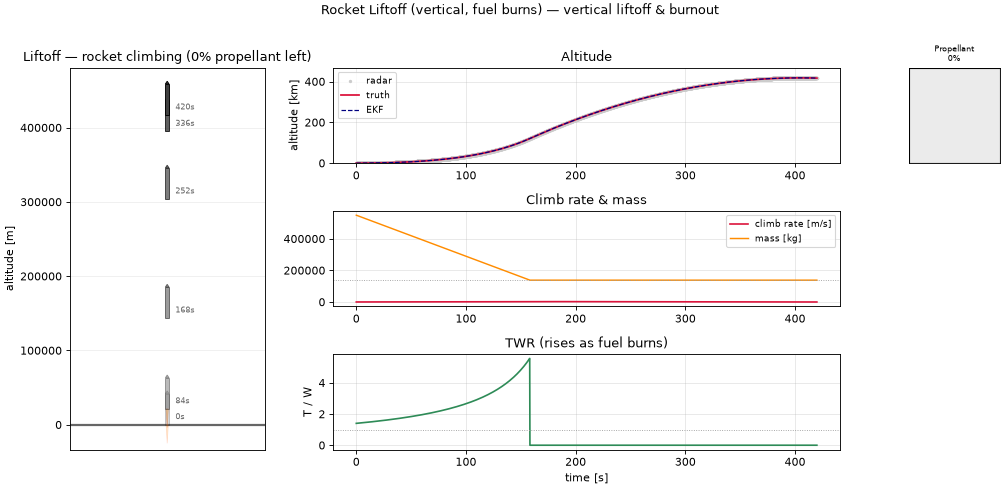

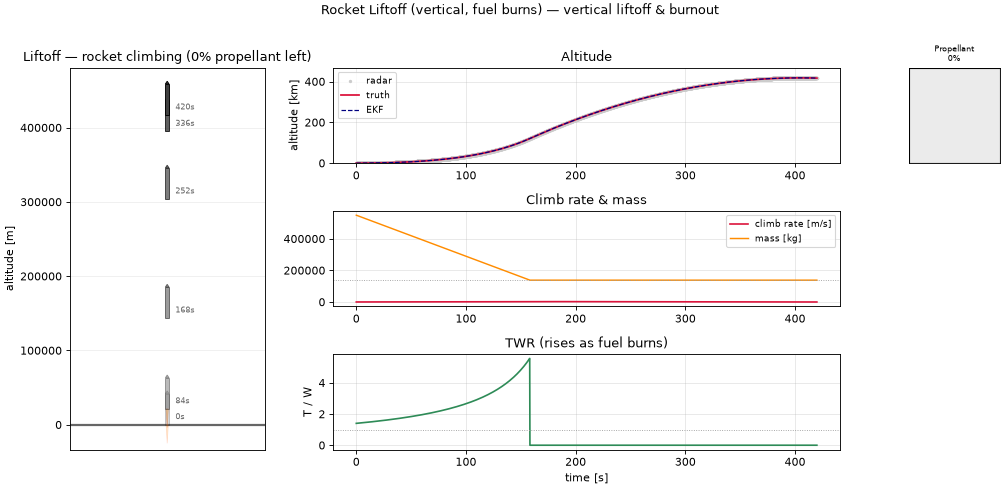

In [2]:
# A Falcon-9-class first stage (orbital launcher), in round numbers:
#   m0   = 549 t   wet mass at liftoff (stage + upper stage + payload)
#   m_dry= 138 t   mass at burnout (everything except the first-stage propellant)
#   ve   = 2900 m/s effective exhaust velocity  (Isp ~ 296 s)
#   mdot = 2600 kg/s propellant flow  ->  thrust = ve*mdot ~ 7.5 MN, liftoff TWR ~ 1.4
# q_mass=0: propellant burn is deterministic, so the mass state carries no process noise
# (a positive mass kick would otherwise momentarily re-ignite a spent engine).
liftoff = RocketLiftoffModel("LIFTOFF", m0=549_000.0, m_dry=138_000.0,
                             ve=2900.0, mdot=2600.0, drag_area=8.0,
                             length=70.0, width=3.7, fs=10.0, track_m=50.0,
                             q_mass=0.0)
liftoff.initial_state([0.0, 0.0, liftoff.m0], P0=np.diag([50.0**2, 10.0**2, 50.0**2]))
flight = liftoff.sample(420.0)                # ~7 min: liftoff -> burnout -> coast to apogee
est    = liftoff.filter(flight.zk)
print({k: round(v, 2) for k, v in liftoff.metrics(flight).items()})
liftoff.plot(est, sample=flight)

### Step 1b — Interactive Liftoff

The animation shows the rocket climbing off the pad. Its flame length scales with
throttle. The propellant gauge drains as the engine burns fuel. This makes the
rocket equation visible.


In [3]:
liftoff.plot(est, sample=flight, interactive=True)

## Step 2 — Guided Ascent: Thrust as a Control Input

This step models a planar climb. The state is `x = [x, y, vx, vy]`. The control
input is 2-D: `u = [ax, ay]`, the thrust-acceleration program (`l = 2`).

The model follows a gravity-turn pitch schedule. The rocket starts nearly vertical
off the pad. It then tips steadily toward the horizon as speed builds. The EKF
tracks the powered flight path from noisy position fixes, the same way engineers
track a real launch.

Over about 8 minutes of burn at about 2.4 g, the stage:
- Climbs to an insertion altitude of about 1300 km.
- Arcs about 1200 km downrange.
- Accelerates to about 7.8 km/s. This is slightly above local orbital velocity. (The
  printout reports speed as a fraction of the local circular-orbit speed.)

This last number is the point of a launch. Reaching orbit means moving sideways fast
enough, not just moving up.


In [4]:
from kalman.runtime.astro import LU

ascent = RocketAscentModel(dt_s=2.0, track_km=1.0)
N = 240                                       # 480 s of powered flight (~8 min to orbit)
uk = np.zeros((N, 2))
for i in range(N):
    frac  = i / (N - 1)
    # Gravity turn: start almost vertical (89 deg above horizon) and pitch over
    # toward horizontal (~5 deg) as horizontal speed builds — measured from horizontal,
    # so ax = a*sin(pitch) is vertical and ay = a*cos(pitch) is downrange (u feeds
    # directly into the model's [x, y] = [vertical, downrange] acceleration).
    pitch = np.deg2rad(89.0 - 84.0 * frac)
    accel = 24.0                              # thrust acceleration [m/s^2] (~2.4 g)
    uk[i] = [accel * np.sin(pitch), accel * np.cos(pitch)]
ascent.initial_state(np.array([[R_EARTH], [0], [0], [0]]),
                     P0=np.diag([(1*KM)**2, (1*KM)**2, 0.01**2, 0.01**2]))
asc = ascent.sample(N / ascent.fs, uk=uk)
est = ascent.filter(asc.zk, uk)

# Readout: where the gravity turn leaves us — altitude, downrange and speed vs orbital.
xf      = np.asarray(asc.xk)[-1]
r       = np.hypot(xf[0], xf[1])                       # geocentric radius [Mm]
alt_km  = (r - R_EARTH) * LU / 1e3
down_km = xf[1] * LU / 1e3
speed   = np.hypot(xf[2], xf[3])                       # km/s
v_circ  = np.sqrt(GM_EARTH / r)                        # local circular speed [km/s]
print(f"insertion: altitude {alt_km:6.1f} km   downrange {down_km:7.1f} km   "
      f"speed {speed:5.2f} km/s  ({speed/v_circ:4.0%} of orbital)")

insertion: altitude 1322.3 km   downrange  1217.9 km   speed  7.83 km/s  (109% of orbital)


### Step 2b — Interactive Ascent

The rocket pitches over along its velocity vector during the gravity turn. The
circular attitude reticle, an artificial horizon, shows the tilt. The gauge tracks
speed as it approaches orbital velocity.


In [5]:
ascent.plot(est, sample=asc, interactive=True)

## Step 3 — Powered Descent and Landing: The Booster That Steers Itself

This is the main model of the notebook. The booster is a rigid body: a rectangle of
length `L` and width `W`, with a gimballed engine. Its state includes orientation:

$$x = [x,\; y,\; v_x,\; v_y,\; \theta,\; \omega,\; m]$$

Here `θ` is the tilt from vertical, and `ω` is the tilt rate.

An onboard control system closes three loops every step:
- A vertical throttle loop tracks a tapering descent profile.
- An outer loop commands a target tilt `θ_des` to cancel cross-range drift.
- An inner loop gimbals the engine (`δ`) to track that tilt and level the vehicle
  for touchdown.

A radar and an IMU (inertial measurement unit) measure `[x, y, θ]`. The EKF
reconstructs the velocities, the tilt rate, and the remaining propellant.

The figures draw the booster as a tilting rectangle standing on the pad. They also
show a circular attitude reticle and a propellant gauge.

In the example below, the booster starts 350 m above the pad with sideways drift.
It flies itself home and lands upright.


{'touchdown miss [m]': 0.16, 'touchdown speed [m/s]': 0.28, 'final tilt [deg]': 0.36, 'ignition time [s]': 0.0, 'ignition altitude [m]': 2000.0, 'propellant burned [kg]': 159.59}


/Users/marcomeyer/Software/kalman/kalman-framework/share/notebooks/kalman/apps/rocket.py:1241: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


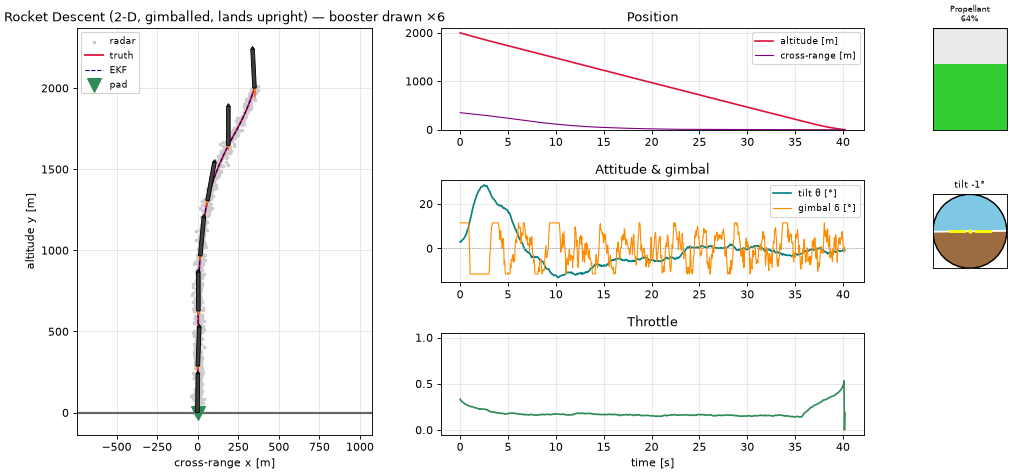

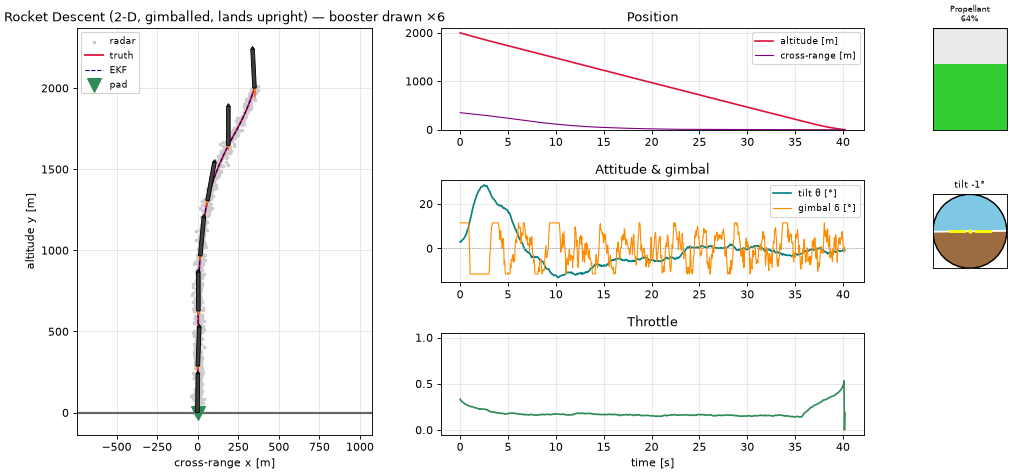

In [6]:
descent = RocketDescentModel(fs=20.0)
x0 = np.array([350.0, 2000.0,   # position: cross-range x, altitude y [m]
               -20.0, -60.0,    # velocity: vx, vy [m/s]
               0.05, 0.0,       # tilt theta [rad], tilt rate omega [rad/s]
               1000.0])         # propellant mass [kg]
descent.initial_state(x0)
land = descent.sample(70.0)
est  = descent.filter(land.zk)
print({k: round(v, 2) for k, v in descent.metrics(land).items()})
descent.plot(est, sample=land)        # draw the booster as a tilting rectangle along its descent


### Step 3b — Interactive Descent

Press play, or move the slider, to watch the booster land. The animation draws the
rocket body, nose, and a throttle-scaled flame. Gimbal control tilts the booster to
cancel its cross-range drift, and it settles on the pad.


In [7]:
descent.plot(est, sample=land, interactive=True)

### Step 3c — The Control Input: Throttle and Gimbal

This step uses the same vehicle, built with `control=True`. This makes the two
actuators an explicit control input: `u = [throttle ∈ [0,1], gimbal δ]`.

The `autopilot()` function computes the guidance law as a control program, `uk`. We
fly this program with `sample(uk=uk)`, and run the EKF with the known controls.

The right-hand panels show the thrust control and the side (gimbal) adjustment the
booster uses to steer.


{'touchdown miss [m]': 0.08, 'touchdown speed [m/s]': 0.0, 'final tilt [deg]': 0.0, 'ignition time [s]': 0.0, 'ignition altitude [m]': 2000.0, 'propellant burned [kg]': 106.61}


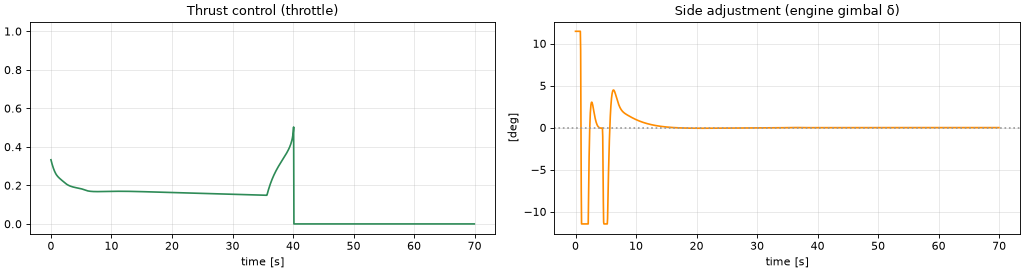

In [8]:
ctl = RocketDescentModel(fs=20.0, control=True)        # l = 2 : [throttle, gimbal]
N = int(70 * ctl.fs)
uk, _ = ctl.autopilot(x0, N)                           # closed-loop guidance -> control program
ctl.initial_state(x0)
land2 = ctl.sample(N / ctl.fs, uk=uk, process_noise=False)
est2  = ctl.filter(land2.zk, uk)

t = np.arange(len(uk)) / ctl.fs
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))

ax[0].plot(t, uk[:, 0], color="seagreen")
ax[0].set_ylim(-0.05, 1.05)
ax[0].set_title("Thrust control (throttle)")
ax[0].set_xlabel("time [s]")
ax[0].grid(alpha=0.3)

ax[1].plot(t, np.degrees(uk[:, 1]), color="darkorange")
ax[1].axhline(0, color="0.6", ls=":")
ax[1].set_title("Side adjustment (engine gimbal δ)")
ax[1].set_xlabel("time [s]")
ax[1].set_ylabel("[deg]")
ax[1].grid(alpha=0.3)

fig.tight_layout()
print({k: round(v, 2) for k, v in ctl.metrics(land2).items()})


## Extensions

- Perturb the descent. Start with more cross-range, a stronger tilt, or wind (extra
  drag). Check that the controller still cancels the error and lands upright.
- Fly the booster manually. Supply your own `uk = [throttle, gimbal]` program to a
  `control=True` model, instead of using `autopilot()`.
- Tighten the sensors (`track_m`, `track_th`), or loosen the process noise `q_*`.
  Observe how the EKF trades smoothness against responsiveness.
- Continue to **08 — Space Science**, which flies to the Moon and on to Mars.
